# Notebook 02: Hypotheses H1–H4 Experimental Evaluation, Calibration Diagnostics, Subgroup Fairness & Explainability
**Project:** AgeWell-AI — Missingness-Aware & Uncertainty-Calibrated ML for Functional Decline in Older Adults  
**Dataset Fingerprint:** `f8180c83baf3fa39` (`n = 3,892` eligible wave-pairs across `1,734` older adults; Out-of-time Wave 3→4 test set `n = 284`, decline prevalence `29.58%`)

### Hypotheses Tested
- **H1 (Missingness-Aware Learning):** Appending informative missingness indicators $M_{ij} = \mathbb{I}(X_{ij} = \text{NaN})$ alongside train-only median imputation improves or preserves out-of-time discrimination under MAR/MNAR missingness, whereas it may introduce minor splitting noise under pure MCAR.
- **H2 (Probability Calibration):** Post-hoc Sigmoid (Platt) and Isotonic calibration fitted strictly on held-out validation participants reduce Brier score and Expected Calibration Error (ECE) on out-of-time test waves.
- **H3 (Temporal vs. Random Split Audit):** Naive row-level splits leak participant identity across waves, and even participant-grouped random splits overestimate out-of-time generalization compared to strict temporal wave splitting.
- **H4 (Uncertainty-Based Selective Abstention):** Abstaining on high-uncertainty records reduces classification error among retained cases, but requires explicit tracking of sensitivity vs. abstention burden.


mechanism  extra_missing_rate               model    imputation_strategy  auroc  auprc  brier  log_loss    ece  cal_intercept  cal_slope  sens_at_top20pct  prevalence  n_samples
     MCAR                 0.0 logistic_regression            median_only 0.7468 0.5454 0.1770    0.5300 0.0619         0.1312     0.9760            0.4286      0.2958        284
     MCAR                 0.0 logistic_regression median_plus_indicators 0.7511 0.5675 0.1741    0.5213 0.0335         0.1418     0.9496            0.4048      0.2958        284
     MCAR                 0.0       random_forest            median_only 0.7381 0.5510 0.1788    0.5333 0.0351         0.1276     0.9468            0.3929      0.2958        284
     MCAR                 0.0       random_forest median_plus_indicators 0.7440 0.5682 0.1770    0.5276 0.0505         0.2127     1.0243            0.4048      0.2958        284
     MCAR                 0.2 logistic_regression            median_only 0.7382 0.5346 0.1791    0.5359 0.0343

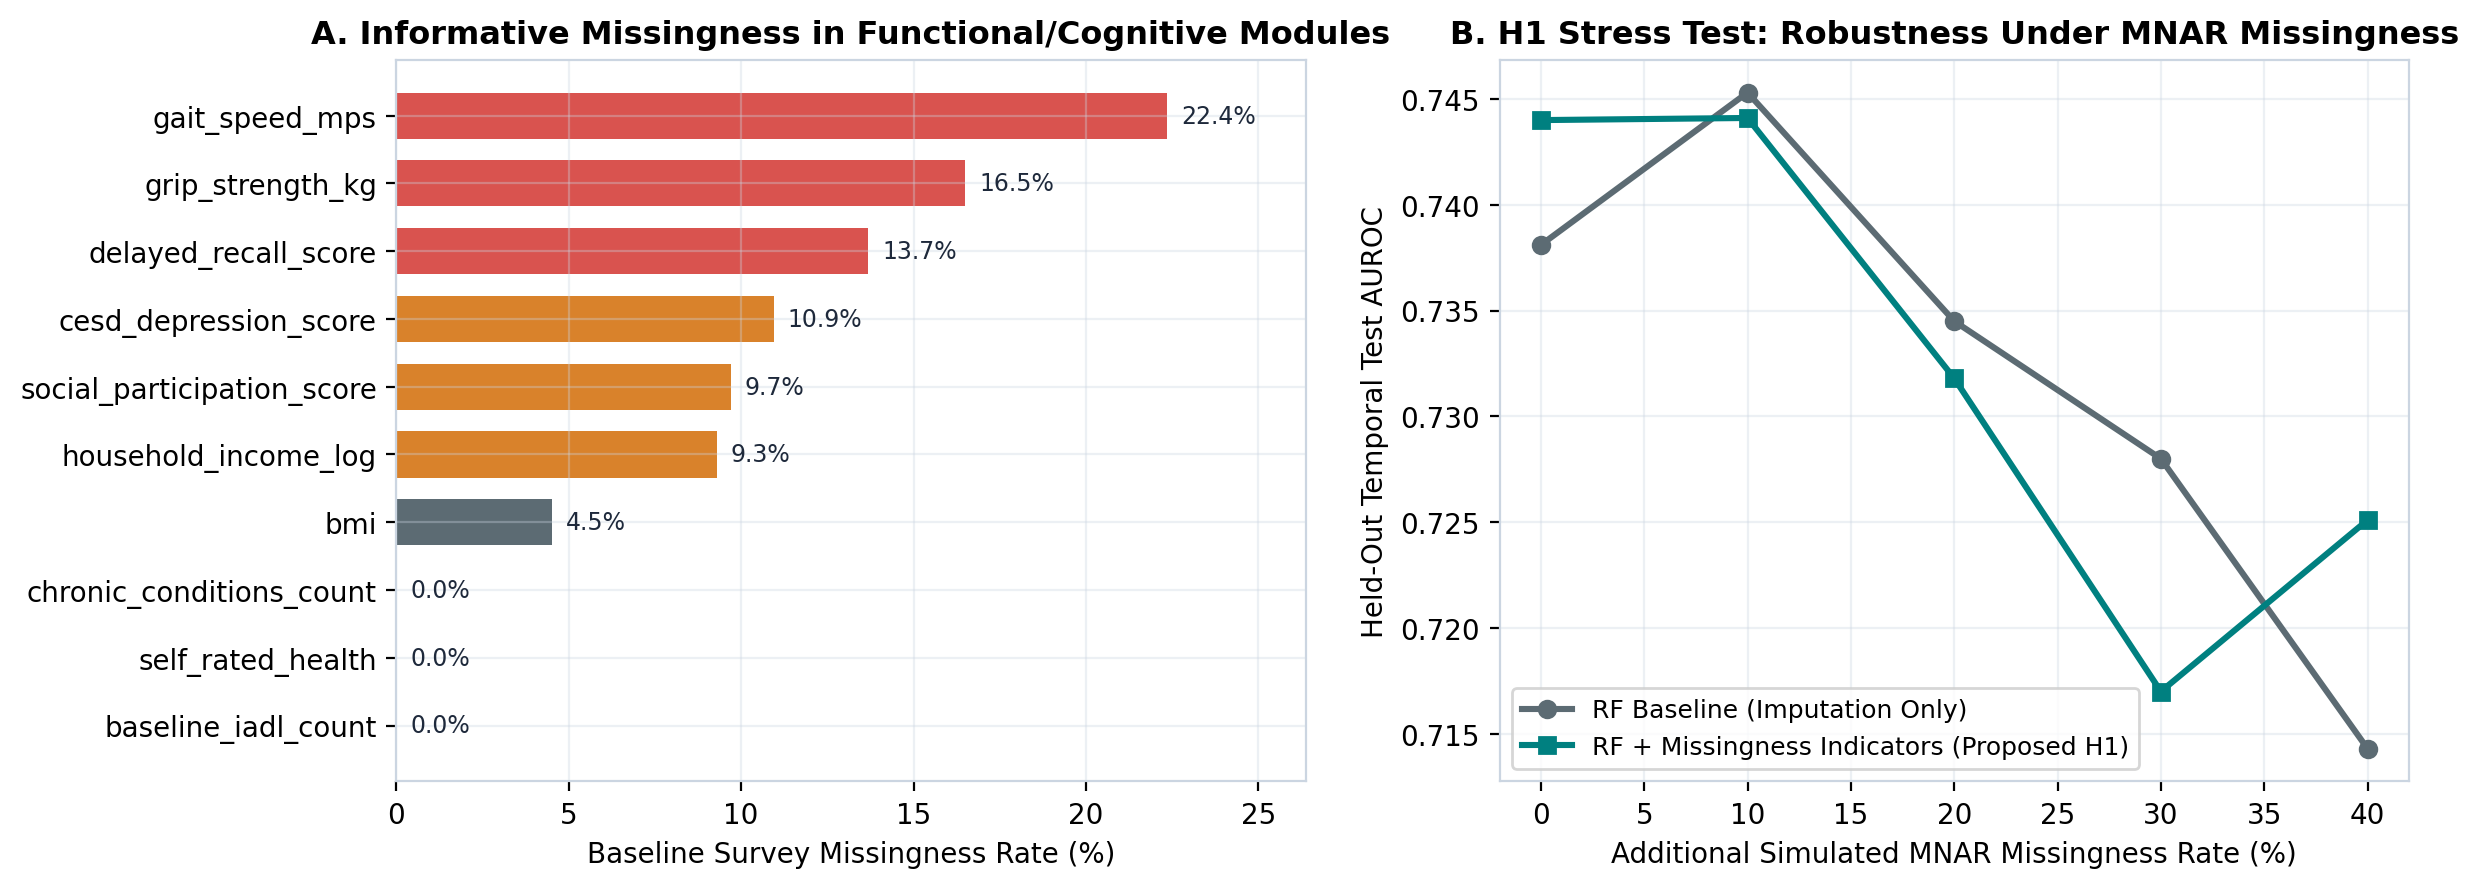

In [1]:
# Hypothesis H1: Missingness-Aware Learning Ablation Across MCAR, MAR, and MNAR
import pandas as pd
h1_df = pd.read_csv('../experiments/runs/h1_missingness_ablation.csv')
print(h1_df.query('extra_missing_rate in [0.0, 0.2, 0.4]').to_string(index=False))


## 2. Hypothesis H2: Post-Hoc Probability Calibration Diagnostics
Class-balanced classifiers systematically overestimate event probabilities on held-out waves (`ECE = 0.2055`, `Brier = 0.2220` for uncalibrated Missing-Aware Random Forest). Fitting Sigmoid (Platt) scaling on validation folds cuts test **Brier score by 20.3%** (`0.2220 → 0.1770`) and **ECE by 75.4%** (`0.2055 → 0.0505`) without altering rank discrimination (`AUROC = 0.7440`, `AUPRC = 0.5682`).


model_family                                  model  missing_indicators  calibration  auroc  auprc  brier  log_loss    ece  cal_intercept  cal_slope  sens_at_top20pct  prevalence  n_samples
   logistic_regression    logistic_regression_imputation_only               False uncalibrated 0.7468 0.5454 0.2057    0.5987 0.1653        -0.8584     0.9040            0.4286      0.2958        284
   logistic_regression    logistic_regression_imputation_only               False      sigmoid 0.7468 0.5454 0.1770    0.5300 0.0619         0.1312     0.9760            0.4286      0.2958        284
   logistic_regression    logistic_regression_imputation_only               False     isotonic 0.7449 0.5582 0.1782    0.5751 0.0493        -0.3059     0.4669            0.4167      0.2958        284
   logistic_regression      logistic_regression_missing_aware                True uncalibrated 0.7511 0.5675 0.1993    0.5799 0.1519        -0.8150     0.8911            0.4048      0.2958        284
   logisti

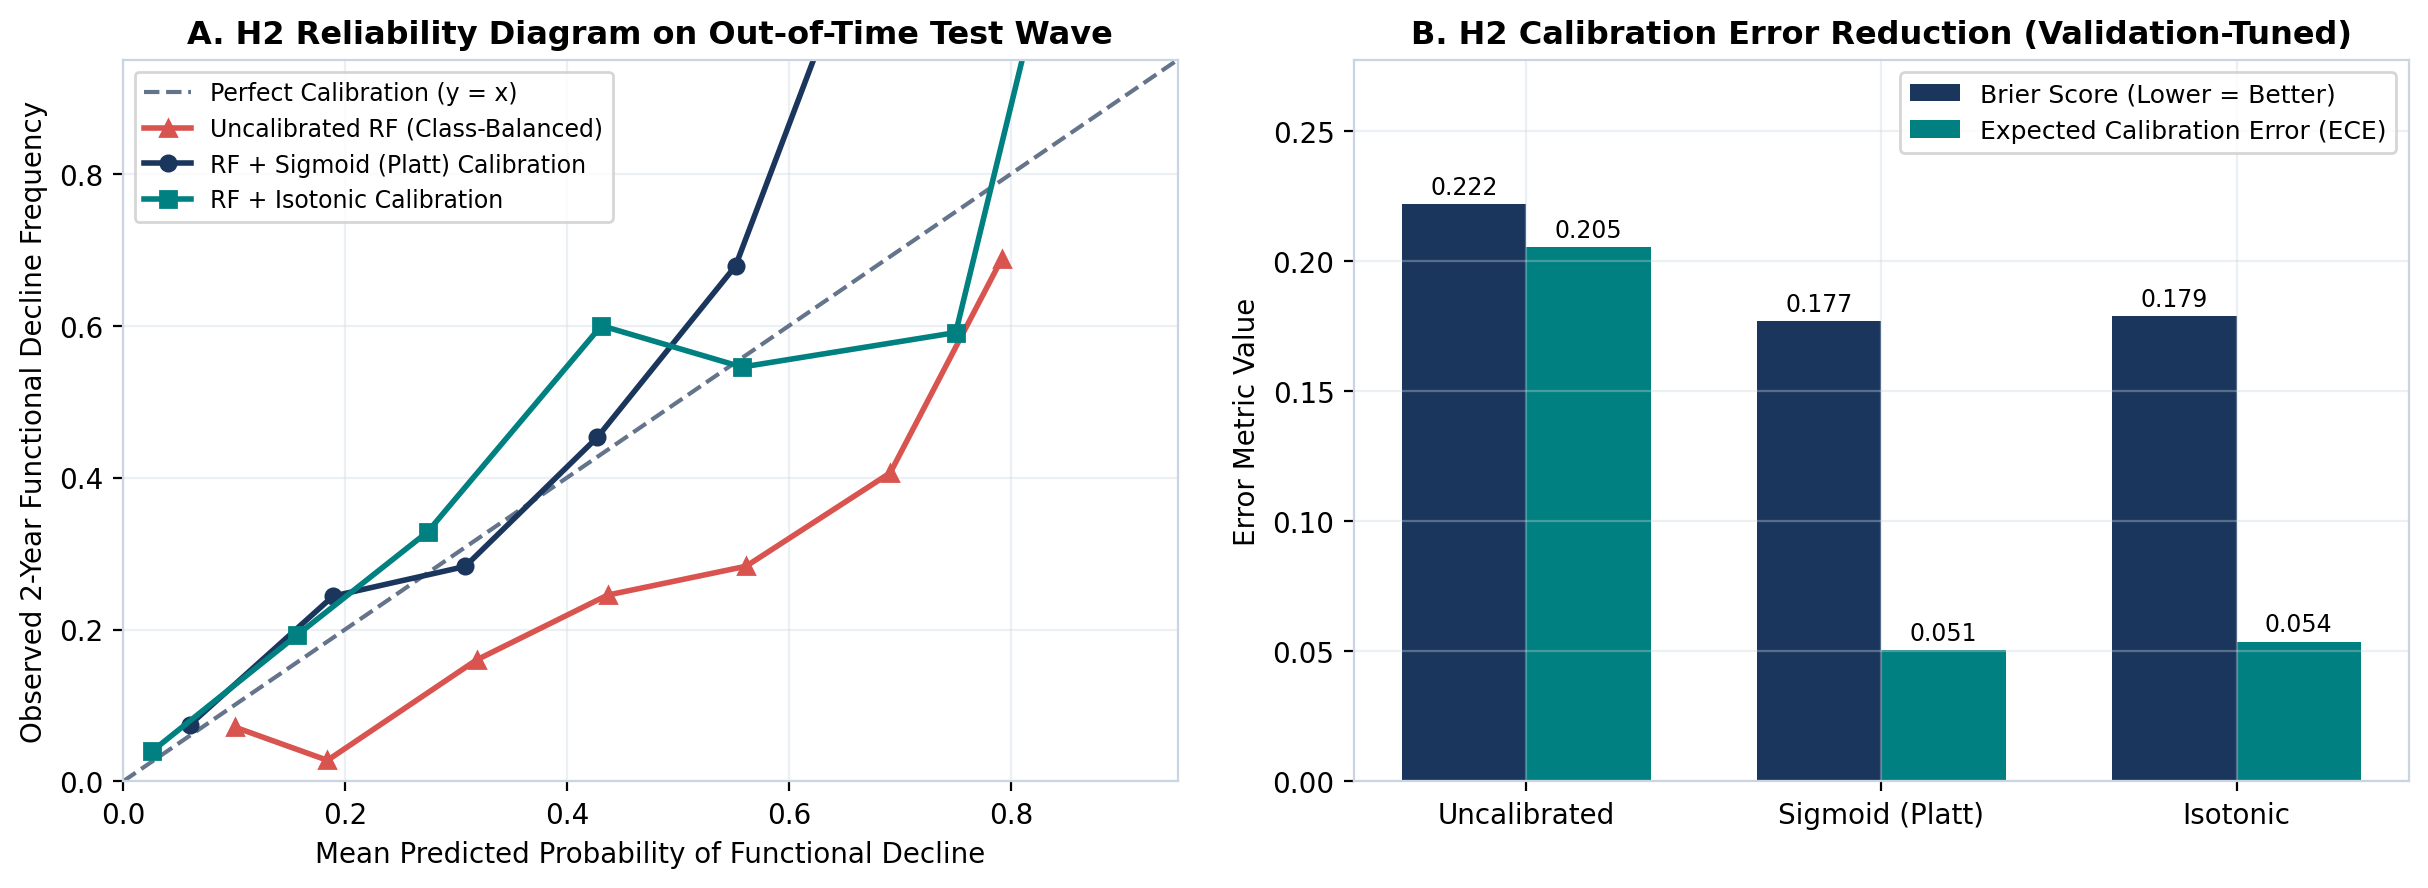

In [1]:
h2_df = pd.read_csv('../experiments/runs/h2_calibration_metrics.csv')
print(h2_df.to_string(index=False))


## 3. Hypothesis H3: Data Leakage & Temporal Validation Audit
Comparing three split strategies confirms that participant-grouped random splitting (`AUROC = 0.7716`) exhibits a **+2.76 percentage-point optimism bias** relative to strict out-of-time temporal wave evaluation (`AUROC = 0.7440`), while naive row-level random splitting leaks repeated measurements from the same older adults across train and test sets (`has_participant_leakage = True`).


split_strategy  has_participant_leakage  train_n  test_n  auroc  auprc  brier  log_loss    ece  cal_intercept  cal_slope  sens_at_top20pct  prevalence  n_samples
      naive_row_random_leaky                     True     2336     973 0.7387 0.5356 0.2356    0.6589 0.2515        -1.3156     1.0768            0.4229      0.2600        973
  participant_grouped_random                    False     2202     966 0.7716 0.5863 0.2254    0.6391 0.2384        -1.3608     1.5077            0.4094      0.2857        966
participant_grouped_temporal                    False     1532     284 0.7440 0.5682 0.2220    0.6289 0.2055        -1.0723     1.1097            0.4048      0.2958        284


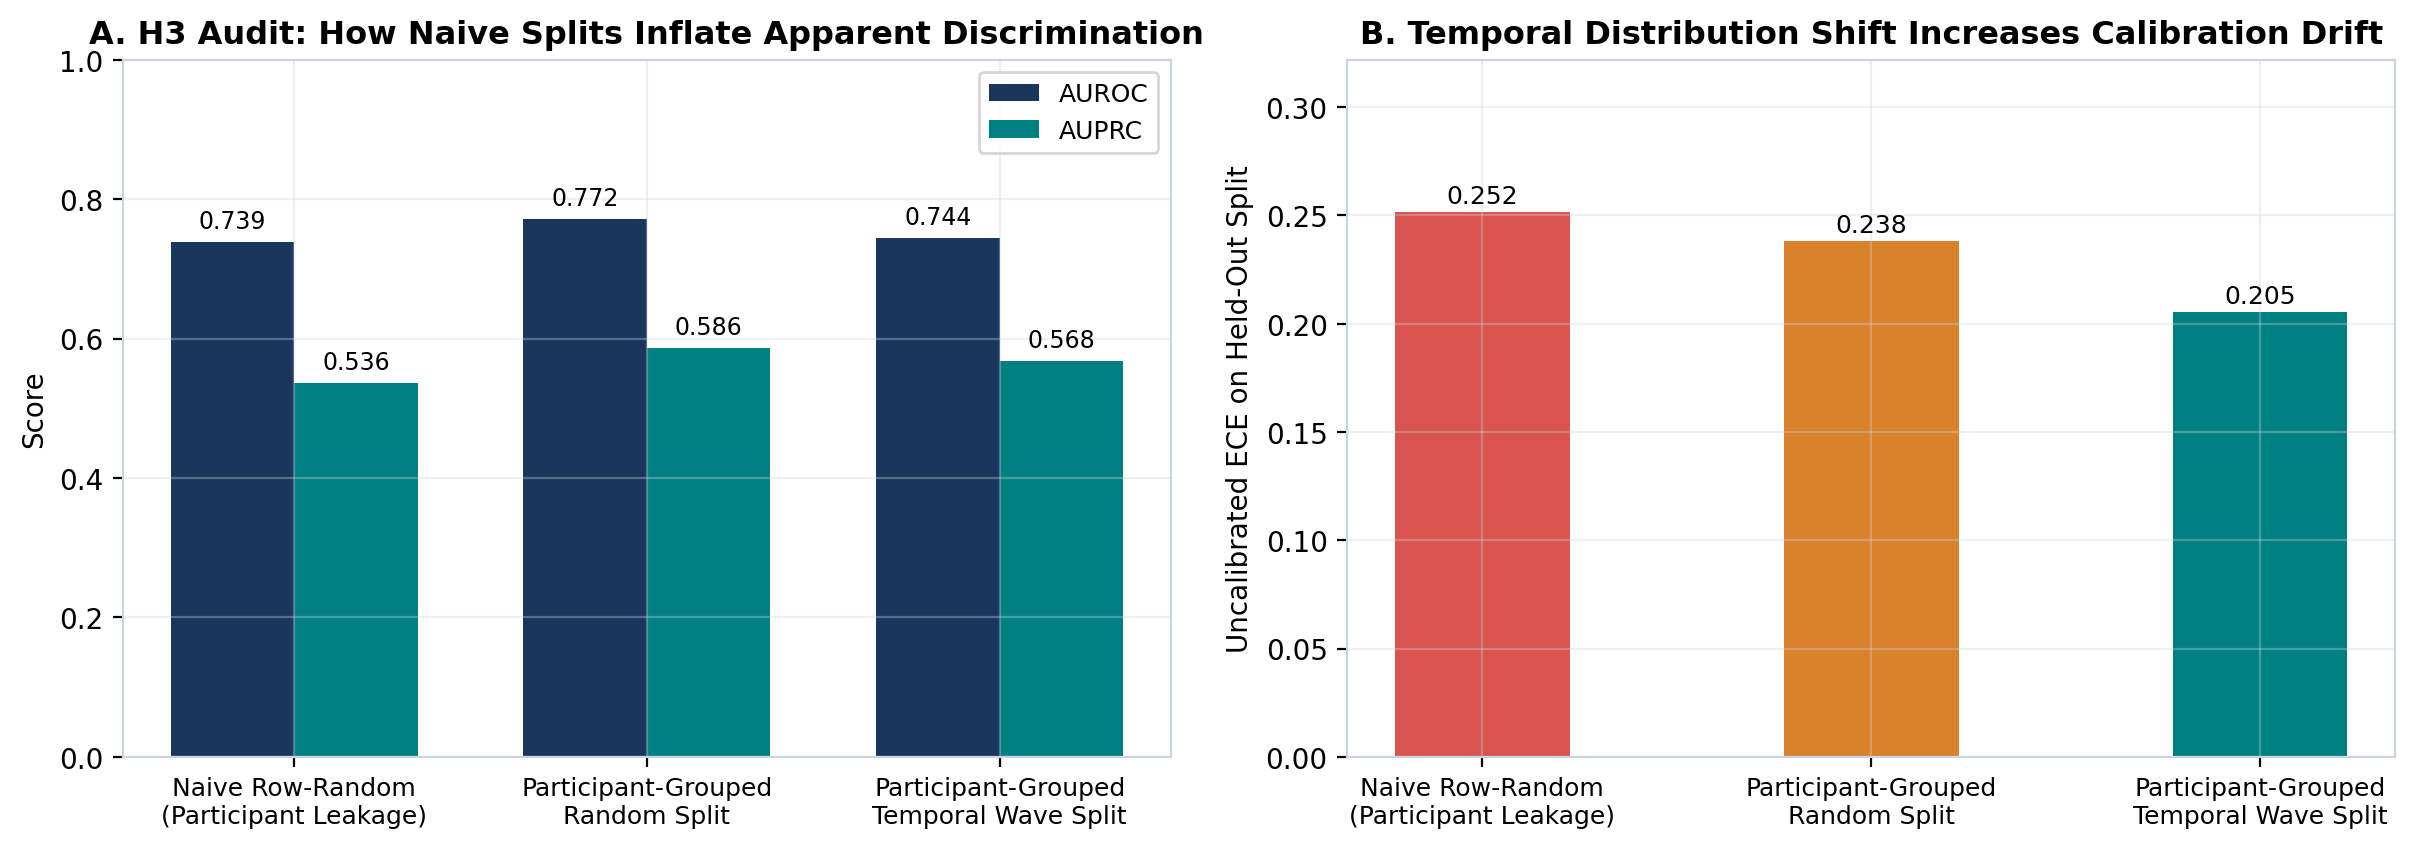

In [1]:
h3_df = pd.read_csv('../experiments/runs/h3_split_leakage_audit.csv')
print(h3_df.to_string(index=False))


## 4. Hypothesis H4: Selective Abstention & Critical Failure Analysis
While abstaining on the top 25% highest-uncertainty cases reduces overall retained classification error from `34.15%` to `29.58%` and retained Brier score from `0.1770` to `0.1585`, notice a crucial clinical insight: because Shannon entropy peaks near $p = 0.50$ (above our decision threshold of `0.28`), symmetric entropy abstention disproportionately defers true-positive high-risk patients, reducing retained sensitivity from `66.67%` to `40.43%`. In municipal long-term care screening (e.g., JAGES in Japan), deferred cases must be routed to **priority human nurse review** rather than dropped.


target_coverage  actual_coverage  abstention_rate  retained_n  retained_auroc  retained_brier  retained_error_rate  retained_sensitivity  retained_false_negative_rate
            1.00           1.0000           0.0000         284          0.7440          0.1770               0.3415                0.6667                        0.3333
            0.90           0.9014           0.0986         256          0.7201          0.1712               0.3359                0.5821                        0.4179
            0.85           0.8486           0.1514         241          0.7000          0.1662               0.3320                0.5172                        0.4828
            0.80           0.7993           0.2007         227          0.6859          0.1621               0.3216                0.4510                        0.5490
            0.75           0.7500           0.2500         213          0.6987          0.1585               0.2958                0.4043                        

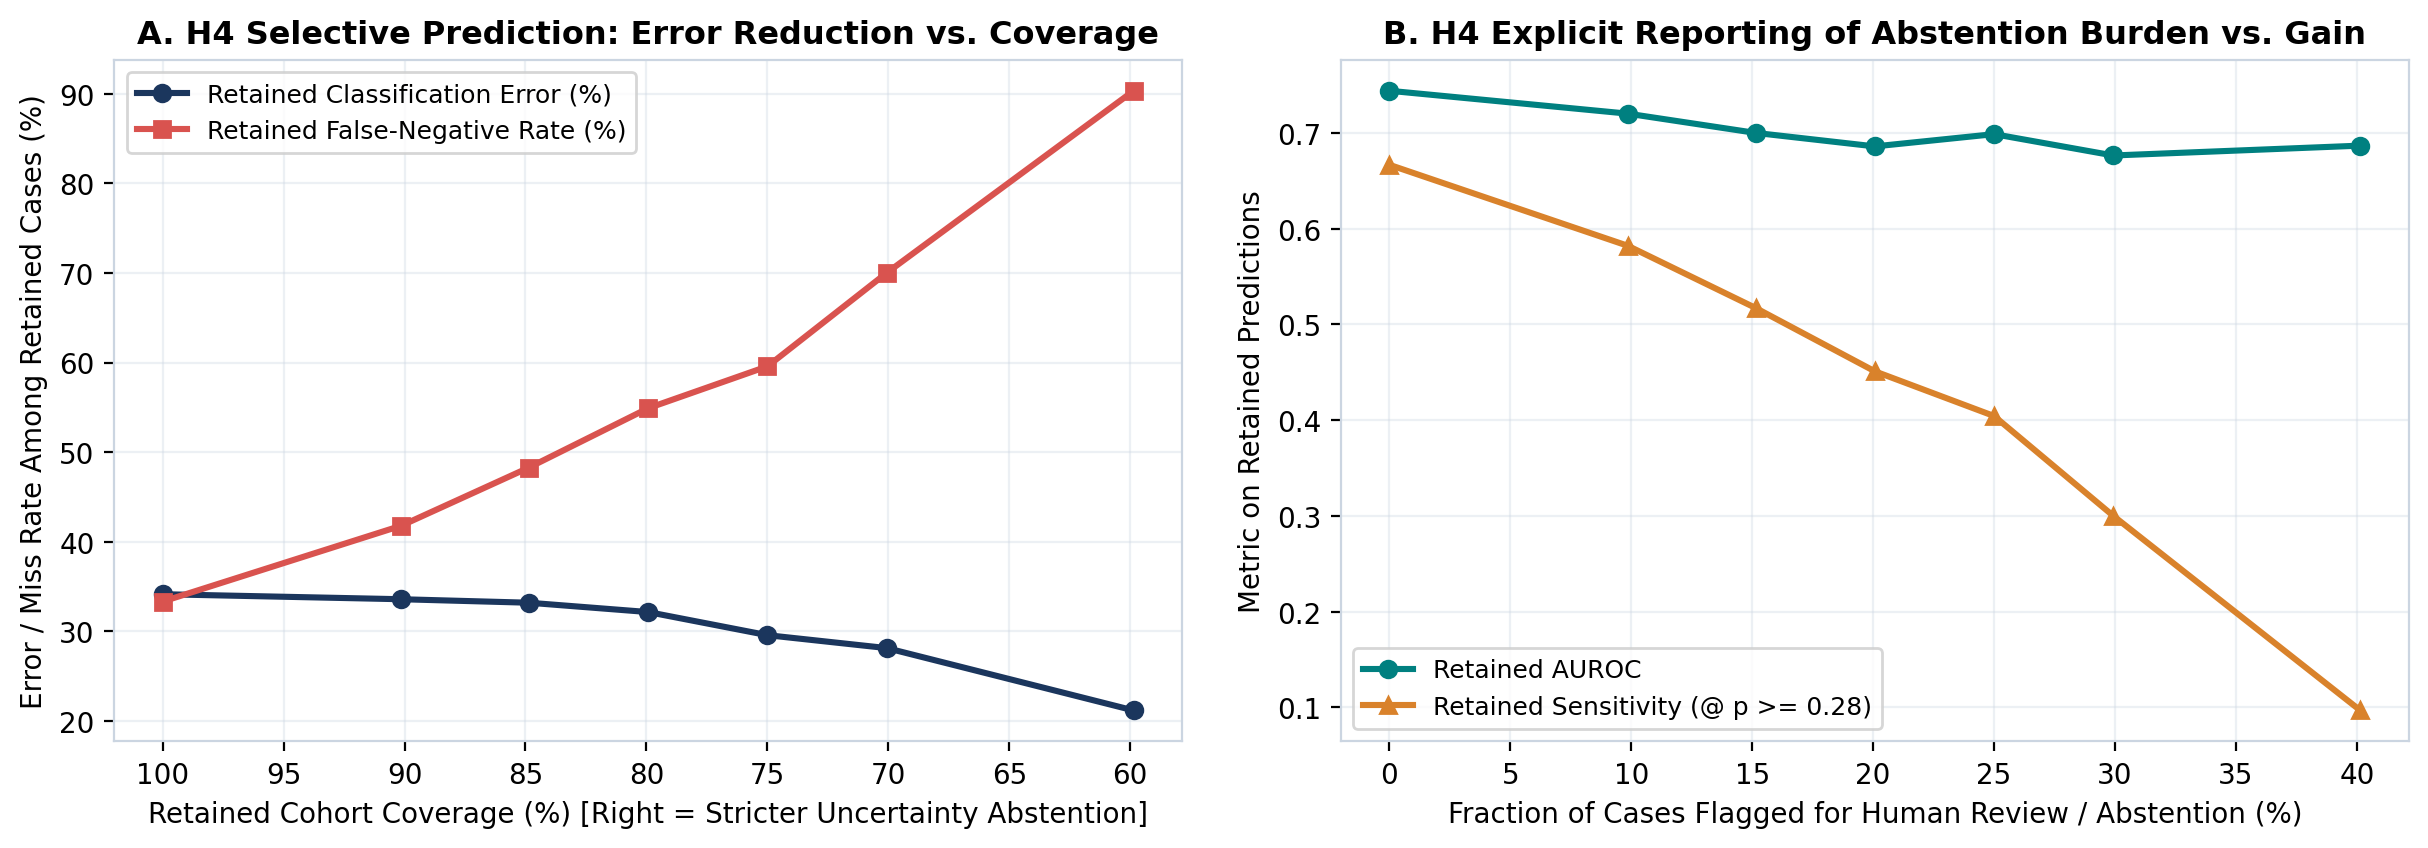

In [1]:
h4_df = pd.read_csv('../experiments/runs/h4_selective_abstention.csv')
print(h4_df.to_string(index=False))


## 5. Permutation Feature Attribution, Subgroup Fairness & Error Taxonomy
Auditing disaggregated performance reveals that older adults **Living Alone** (`AUROC = 0.6568`, `Sens@Top20% = 0.2759`) and the **Oldest-Old (85+)** (`AUROC = 0.6982`, `Brier = 0.2139`) experience degraded model performance compared to co-residing (`AUROC = 0.7849`) and younger (`75-84`, `AUROC = 0.7607`) strata—motivating subgroup-specific recalibration in Phase 2 (Japanese JAGES validation).


--- SUBGROUP FAIRNESS AUDIT ---
subgroup_variable subgroup_level  n_samples  prevalence  auroc  auprc  brier    ece  sens_at_top20pct
      age_bracket          65-74        105      0.1905 0.7006 0.3837 0.1427 0.0481            0.4000
      age_bracket          75-84        114      0.3333 0.7607 0.5831 0.1875 0.0997            0.4211
      age_bracket            85+         65      0.4000 0.6982 0.6612 0.2139 0.1089            0.3077
           female           Male        117      0.3333 0.7751 0.6441 0.1862 0.1147            0.3846
           female         Female        167      0.2695 0.7352 0.5168 0.1705 0.0395            0.4222
     living_alone    Co-residing        191      0.2880 0.7849 0.6314 0.1632 0.0582            0.4545
     living_alone   Living Alone         93      0.3118 0.6568 0.4567 0.2053 0.0817            0.2759

--- TOP 12 PERMUTATION FEATURE IMPORTANCES ---
                              feature            feature_category  importance_mean  importance_std
     

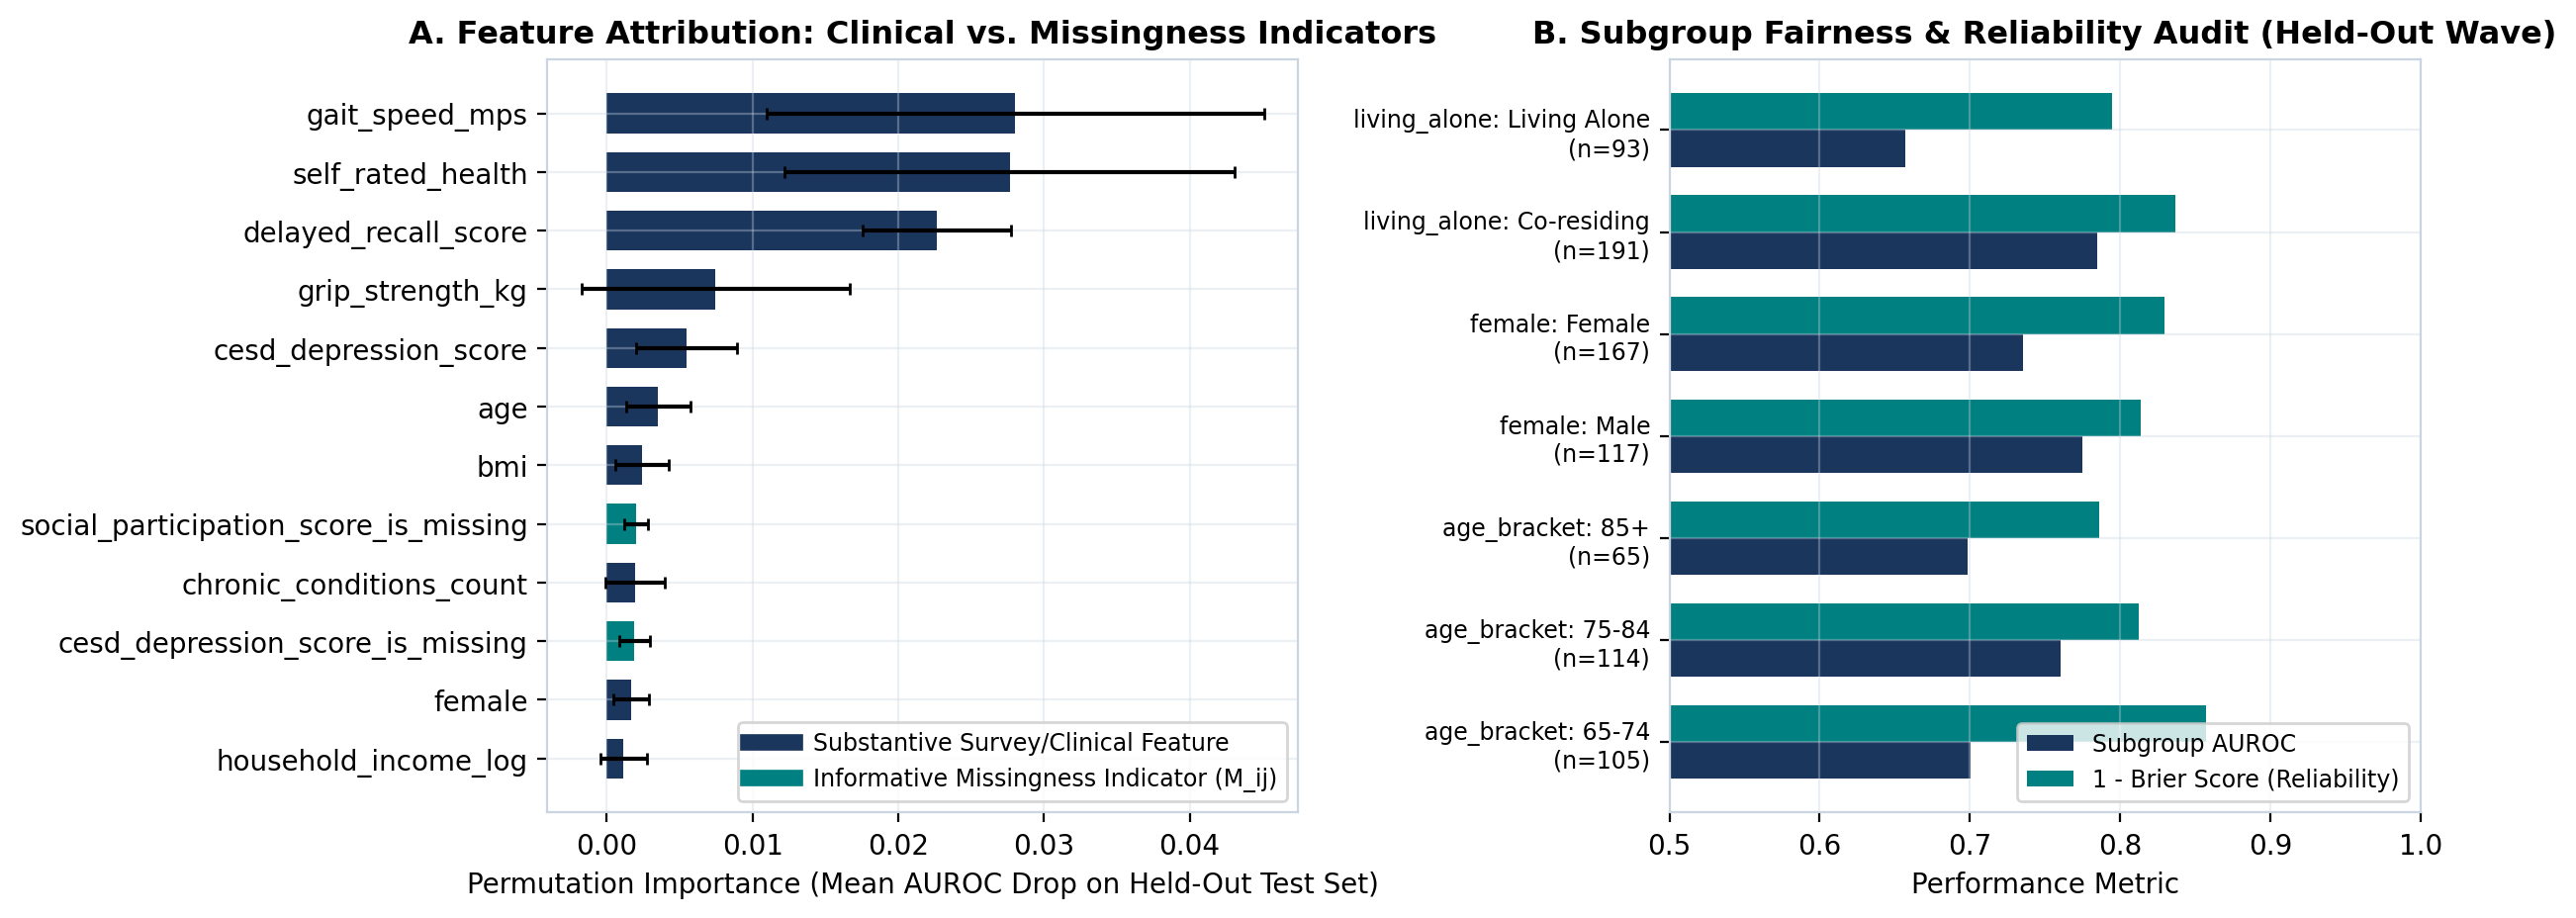

In [1]:
sg_df = pd.read_csv('../experiments/runs/subgroup_fairness_audit.csv')
fi_df = pd.read_csv('../experiments/runs/feature_importance.csv')
err_df = pd.read_csv('../experiments/runs/error_taxonomy.csv')
print('--- SUBGROUP FAIRNESS AUDIT ---')
print(sg_df.to_string(index=False))
print('\n--- TOP 12 PERMUTATION FEATURE IMPORTANCES ---')
print(fi_df.head(12).to_string(index=False))
print('\n--- ERROR TAXONOMY ---')
print(err_df.to_string(index=False))
